# Module 20 Capstone — Quality-Linked Predictive Maintenance for Display Lamination

**Research question:** Can tool-health signals and lamination-process telemetry at the end of a production cycle predict whether the **next cycle's bondline thickness (BLT) measurement will be out of specification**?

**Primary supervised target:** `next_blt_out_of_spec` — 1 if the next cycle's measured BLT lies outside the configured engineering limits; 0 otherwise. This is a **quality-risk proxy for equipment degradation**, not a direct machine-breakdown or remaining-useful-life prediction. Demonstrating maintenance impact requires validated maintenance interventions and tool-event records.

**Module 20 work:** data quality, cleaning, exploratory data analysis, feature engineering, visualizations, one interpretable logistic-regression baseline, and a validation strategy. **Module 24:** stronger models and validation against real line data.

> **Data integrity:** No proprietary lamination logs were supplied with this assignment. The notebook runs in an explicitly labeled **SYNTHETIC DEMONSTRATION** mode unless a real `data/lamination_telemetry.csv` is provided. Synthetic outputs must not be presented as factory findings or validated equipment performance. The example BLT limits (95–105 µm) are illustrative, **not an engineering specification**. Never put confidential line telemetry into a public GitHub repository.

## 1. Libraries and configuration

A real dataset must have one record per tool/cycle, a timestamp, tool identifier, one measured BLT field, and predictors available at the **prediction time**. The code does not use the *future* BLT measurement as a feature.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, balanced_accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay, roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_SEED = 42
REAL_DATA_PATH = Path("data/lamination_telemetry.csv")
BLT_LOWER_UM = 95.0     # SYNTHETIC DEMO LIMIT; replace with approved process spec
BLT_UPPER_UM = 105.0    # SYNTHETIC DEMO LIMIT; replace with approved process spec
ROLLER_FORCE_SETPOINT_KGF = 10.0  # SYNTHETIC demo reference

sns.set_theme(style="whitegrid", context="notebook")

## 2. Data source and reproducible demonstration generator

The generator simulates drifting sensor readings and correlated BLT outcomes across five fictional tools. These correlations are *programmed into the demonstration*; they do **not** establish actual engineering causality. When the real CSV is present, it takes precedence automatically.

**Expected input columns:**

| Column | Meaning |
|---|---|
| `timestamp`, `tool_id` | Cycle timestamp and stable tool identity |
| `roller_force_kgf`, `roller_speed_mm_s`, `sheet_tension_kgf` | Contact/loading parameters |
| `vacuum_kpa`, `motor_current_a`, `temperature_c`, `vibration_rms_mm_s`, `cycle_time_s` | Equipment-health/process indicators |
| `cycles_since_pm` | Cycle counter since preventative maintenance (when available) |
| `blt_um` | Measured BLT for *that cycle*, from metrology joined by cycle ID |

Real systems should join process data and BLT results with a unique `tool_id + cycle_id`, not timestamp alone, when possible.

In [2]:
def generate_synthetic_lamination_data(seed=RANDOM_SEED):
    """Illustrative data only; not measured factory telemetry."""
    rng = np.random.default_rng(seed)
    records = []

    for tool_index in range(5):
        tool_id = f"DEMO-LAM-{tool_index + 1:02d}"
        for cycle in range(430):
            cycles_since_pm = cycle % 160
            drift = cycles_since_pm / 160
            force = 10 + rng.normal(0, 0.27) - 0.45 * drift
            speed = 300 + rng.normal(0, 8) + 9 * drift
            vacuum = -72 + rng.normal(0, 1.1) + 3 * drift
            current = 3.8 + rng.normal(0, 0.12) + 0.55 * drift
            temperature = 34 + rng.normal(0, 0.85) + 2.2 * drift
            vibration = 0.65 + 1.1 * drift + abs(rng.normal(0, 0.15))
            tension = 11 + rng.normal(0, 0.55) + 0.3 * drift
            cycle_time = 4.3 + rng.normal(0, 0.08) + 0.08 * drift

            blt = (
                100 + 3.8 * drift + 2.8 * (10 - force) + 0.25 * (vacuum + 72)
                + 0.12 * (speed - 300) / 8 + rng.normal(0, 1.65)
                + 0.22 * tool_index
            )
            records.append({
                "timestamp": pd.Timestamp("2026-01-01") + pd.Timedelta(minutes=15 * cycle),
                "tool_id": tool_id,
                "roller_force_kgf": force,
                "roller_speed_mm_s": speed,
                "sheet_tension_kgf": tension,
                "vacuum_kpa": vacuum,
                "motor_current_a": current,
                "temperature_c": temperature,
                "vibration_rms_mm_s": vibration,
                "cycle_time_s": cycle_time,
                "cycles_since_pm": cycles_since_pm,
                "blt_um": blt,
            })
    return pd.DataFrame.from_records(records)

if REAL_DATA_PATH.exists():
    raw = pd.read_csv(REAL_DATA_PATH)
    data_mode = "REAL DATA — requires verified permissions, labels, and spec limits"
else:
    raw = generate_synthetic_lamination_data()
    data_mode = "SYNTHETIC DEMONSTRATION — NOT FACTORY RESULTS"

print(data_mode)
print(f"Loaded {len(raw):,} rows × {raw.shape[1]} columns")
display(raw.head(3))

SYNTHETIC DEMONSTRATION — NOT FACTORY RESULTS
Loaded 2,150 rows × 12 columns


,timestamp,tool_id,roller_force_kgf,roller_speed_mm_s,sheet_tension_kgf,vacuum_kpa,motor_current_a,temperature_c,vibration_rms_mm_s,cycle_time_s,cycles_since_pm,blt_um
0,2026-01-01 00:00:00,DEMO-LAM-01,10.082274,291.680127,11.070312,-71.174504,3.912868,32.341620,0.845327,4.274701,0,99.823488
1,2026-01-01 00:15:00,DEMO-LAM-01,9.766866,307.091434,10.529264,-71.125679,3.811361,34.971905,0.727001,4.330000,1,99.419322
2,2026-01-01 00:30:00,DEMO-LAM-01,10.231557,299.713093,10.768170,-72.165849,3.725163,35.066660,0.686929,4.272829,2,100.231686


## 3. Dataset audit and cleaning

We check schema, missingness, duplicated tool/timestamp records, descriptive statistics and plausibility. **Do not automatically remove sensor outliers**: extremes can be early warning signals. We impute missing predictor values *inside* the training pipeline to prevent test-set leakage. A missing target BLT cannot safely be classified as in-spec.

In [3]:
required_columns = [
    "timestamp", "tool_id", "blt_um", "roller_force_kgf", "roller_speed_mm_s",
    "vacuum_kpa", "motor_current_a", "vibration_rms_mm_s", "temperature_c",
    "sheet_tension_kgf", "cycle_time_s", "cycles_since_pm",
]
missing_columns = sorted(set(required_columns) - set(raw.columns))
if missing_columns:
    raise ValueError(f"Required columns missing: {missing_columns}. Map your CSV schema first.")

data = raw.copy()
data["timestamp"] = pd.to_datetime(data["timestamp"], errors="coerce")
for col in set(required_columns) - {"timestamp", "tool_id"}:
    data[col] = pd.to_numeric(data[col], errors="coerce")

print("Missing fields by column:")
display(data.isna().sum().sort_values(ascending=False).to_frame("missing_rows"))
print("Duplicates by tool_id + timestamp:", data.duplicated(["tool_id", "timestamp"]).sum())
print("Numeric overview:")
display(data.select_dtypes(include="number").describe().round(2))

n_raw = len(data)
data = data.dropna(subset=["timestamp", "tool_id"])
data = data.drop_duplicates(subset=["tool_id", "timestamp"], keep="last")
data = data.sort_values(["tool_id", "timestamp"]).reset_index(drop=True)
print(f"Records removed for missing keys / duplicate tool-timestamps: {n_raw - len(data)}")

# Flag possible anomalies for engineering review, rather than discarding them.
measurement_cols = ["roller_force_kgf", "roller_speed_mm_s", "motor_current_a",
                    "vibration_rms_mm_s", "cycle_time_s"]
anomaly_flags = {}
for col in measurement_cols:
    q1, q3 = data[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    anomaly_flags[col] = int(((data[col] < q1 - 1.5*iqr) |
                              (data[col] > q3 + 1.5*iqr)).sum())
print("IQR flags (investigate; not automatically discarded):", anomaly_flags)

Missing fields by column:


,missing_rows
timestamp,0
tool_id,0
roller_force_kgf,0
roller_speed_mm_s,0
sheet_tension_kgf,0
vacuum_kpa,0
motor_current_a,0
temperature_c,0
vibration_rms_mm_s,0
cycle_time_s,0


Duplicates by tool_id + timestamp: 0
Numeric overview:


,roller_force_kgf,roller_speed_mm_s,sheet_tension_kgf,vacuum_kpa,motor_current_a,temperature_c,vibration_rms_mm_s,cycle_time_s,cycles_since_pm,blt_um
count,2150.00,2150.00,2150.00,2150.00,2150.00,2150.00,2150.00,2150.00,2150.00,2150.00
mean,9.80,304.05,11.14,-70.65,4.05,35.02,1.27,4.34,73.10,103.09
std,0.31,8.54,0.54,1.38,0.20,1.03,0.32,0.08,44.33,2.52
min,8.71,274.06,9.42,-76.17,3.47,31.90,0.66,4.05,0.00,94.31
25%,9.60,298.42,10.78,-71.55,3.91,34.33,1.01,4.28,35.00,101.34
50%,9.81,304.11,11.14,-70.68,4.05,35.00,1.26,4.34,71.00,103.04
75%,10.01,309.53,11.51,-69.72,4.19,35.69,1.51,4.39,107.00,104.83
max,10.98,333.36,13.48,-65.50,4.63,38.20,2.06,4.60,159.00,111.98


Records removed for missing keys / duplicate tool-timestamps: 0
IQR flags (investigate; not automatically discarded): {'roller_force_kgf': 20, 'roller_speed_mm_s': 19, 'motor_current_a': 5, 'vibration_rms_mm_s': 0, 'cycle_time_s': 20}


## 4. Define the **next-cycle** outcome (no future feature leakage)

At the end of cycle *t*, the model can use tool/process signals from cycle *t* to flag possible BLT out-of-specification on cycle *t + 1*. The `blt_um` measurement for cycle *t+1* is **only used to create the retrospective training label**; it is never a predictor. Operational use requires a confirmed metrology-availability timeline and validated BLT control limits.

Each tool's last row lacks a next-cycle label and is excluded. Missing BLT measurements also remain unknown, not negative.

In [4]:
current_blt_status = pd.Series(
    np.where(data["blt_um"].notna(),
             (~data["blt_um"].between(BLT_LOWER_UM, BLT_UPPER_UM)).astype(int),
             np.nan), index=data.index
)
data["blt_out_of_spec"] = current_blt_status

data["next_blt_out_of_spec"] = (
    data.groupby("tool_id", sort=False)["blt_out_of_spec"].shift(-1)
)
data["next_timestamp"] = data.groupby("tool_id", sort=False)["timestamp"].shift(-1)

# Features are computed using only current and preceding observations within each tool.
data["force_deviation_kgf"] = data["roller_force_kgf"] - ROLLER_FORCE_SETPOINT_KGF
for feature in ["roller_force_kgf", "motor_current_a", "vibration_rms_mm_s"]:
    data[f"{feature}_rolling_mean_5"] = (
        data.groupby("tool_id")[feature]
        .transform(lambda series: series.rolling(5, min_periods=1).mean())
    )
data["roller_force_rolling_std_5"] = (
    data.groupby("tool_id")["roller_force_kgf"]
    .transform(lambda series: series.rolling(5, min_periods=2).std())
)

labeled = data.dropna(subset=["next_blt_out_of_spec", "next_timestamp"]).copy()
labeled["next_blt_out_of_spec"] = labeled["next_blt_out_of_spec"].astype(int)
print(f"Labeled samples: {len(labeled):,}")
print("Next-cycle OOS target counts:")
display(labeled["next_blt_out_of_spec"].value_counts().rename(index={0:"Within spec",1:"Out of spec"}).to_frame("cycles"))
print(f"Target prevalence: {labeled['next_blt_out_of_spec'].mean():.1%}")

Labeled samples: 2,145
Next-cycle OOS target counts:


,cycles
next_blt_out_of_spec,
Within spec,1661
Out of spec,484


Target prevalence: 22.6%


## 5. EDA — distributions and conditional quality risk

**EDA questions:** Are current health signals drifting over time? Do measurements differ between cycles preceding an out-of-spec event and those preceding an in-spec event? Which tools/conditions merit closer investigation? Group differences are associations and do not prove causality.

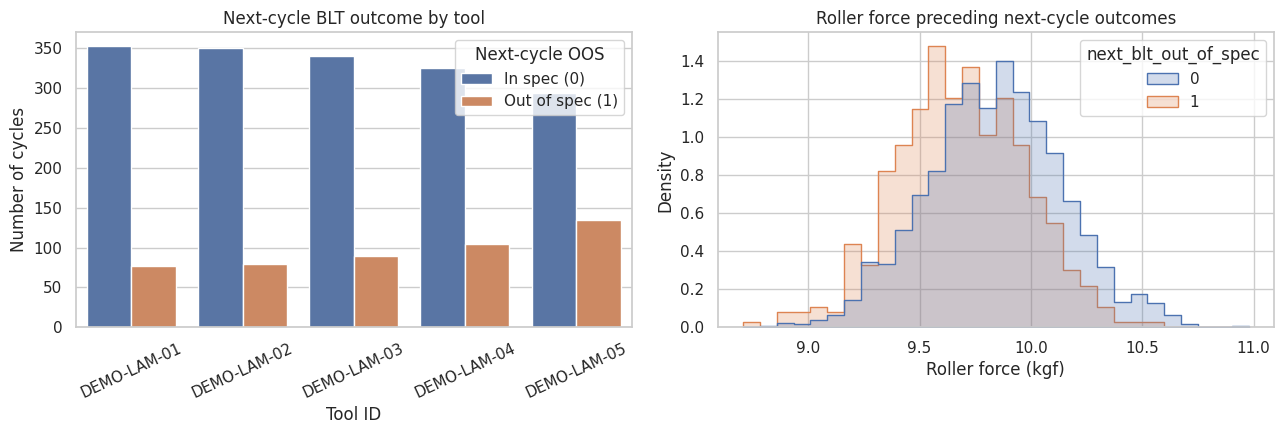

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=labeled, x="tool_id", hue="next_blt_out_of_spec", ax=axes[0])
axes[0].set(title="Next-cycle BLT outcome by tool", xlabel="Tool ID", ylabel="Number of cycles")
axes[0].legend(title="Next-cycle OOS", labels=["In spec (0)", "Out of spec (1)"])
axes[0].tick_params(axis="x", rotation=25)
sns.histplot(data=labeled, x="roller_force_kgf", hue="next_blt_out_of_spec",
             stat="density", common_norm=False, element="step", bins=30, ax=axes[1])
axes[1].set(title="Roller force preceding next-cycle outcomes", xlabel="Roller force (kgf)", ylabel="Density")
plt.tight_layout()
plt.show()

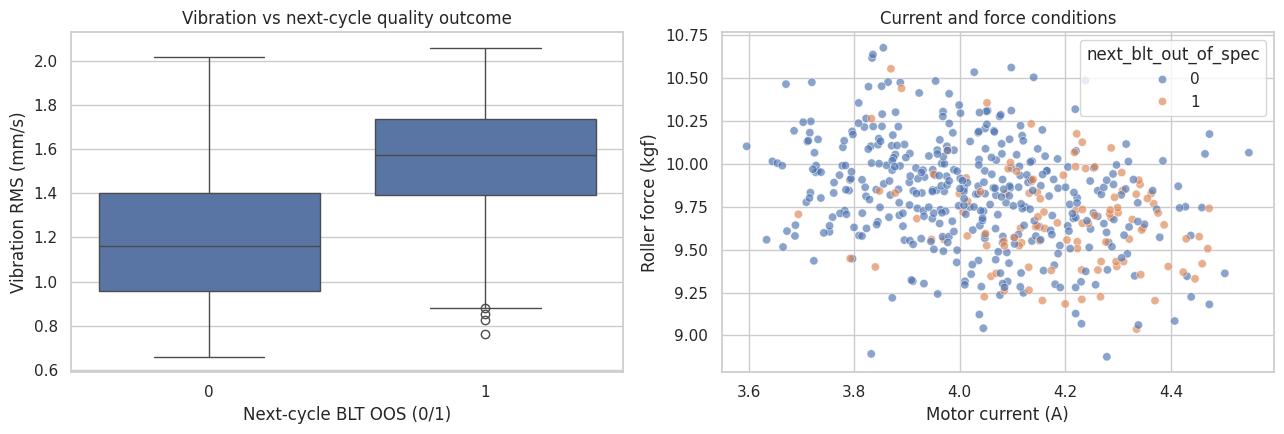

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=labeled, x="next_blt_out_of_spec", y="vibration_rms_mm_s", ax=axes[0])
axes[0].set(title="Vibration vs next-cycle quality outcome", xlabel="Next-cycle BLT OOS (0/1)", ylabel="Vibration RMS (mm/s)")
sns.scatterplot(data=labeled.sample(min(500, len(labeled)), random_state=RANDOM_SEED),
                x="motor_current_a", y="roller_force_kgf", hue="next_blt_out_of_spec",
                alpha=0.65, ax=axes[1])
axes[1].set(title="Current and force conditions", xlabel="Motor current (A)", ylabel="Roller force (kgf)")
plt.tight_layout()
plt.show()

,cycles,events,event_rate
tool_id,,,
DEMO-LAM-05,429,135,31.5%
DEMO-LAM-04,429,104,24.2%
DEMO-LAM-03,429,89,20.7%
DEMO-LAM-02,429,79,18.4%
DEMO-LAM-01,429,77,17.9%


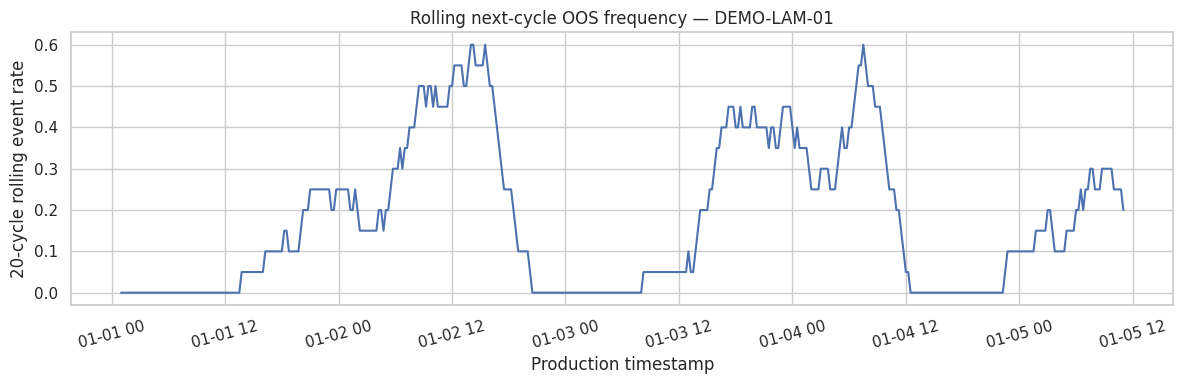

In [7]:
rate_by_tool = (labeled.groupby("tool_id")["next_blt_out_of_spec"]
                .agg(cycles="count", events="sum", event_rate="mean")
                .sort_values("event_rate", ascending=False))
display(rate_by_tool.style.format({"event_rate": "{:.1%}"}))

# A readable time-ordered view for one illustrative tool.
example_tool = labeled["tool_id"].iloc[0]
timeline = labeled.loc[labeled["tool_id"] == example_tool].copy()
timeline["rolling_oos_rate_20"] = timeline["next_blt_out_of_spec"].rolling(20, min_periods=5).mean()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(timeline["timestamp"], timeline["rolling_oos_rate_20"])
ax.set(title=f"Rolling next-cycle OOS frequency — {example_tool}",
       xlabel="Production timestamp", ylabel="20-cycle rolling event rate")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 6. Time-ordered train/test split and feature selection

To avoid leakage from future production, we use the first **80% of timestamps** for training and the remaining 20% for testing. A boundary purge excludes training rows whose **next-cycle label** occurs in the test period. Predictor imputation and scaling are fit *only* on the training portion. For a production deployment, additionally validate on entirely unseen tools, lots, suppliers, and time periods.

In [8]:
numeric_features = [
    "roller_force_kgf", "roller_speed_mm_s", "sheet_tension_kgf",
    "vacuum_kpa", "motor_current_a", "temperature_c", "vibration_rms_mm_s",
    "cycle_time_s", "cycles_since_pm", "force_deviation_kgf",
    "roller_force_kgf_rolling_mean_5", "motor_current_a_rolling_mean_5",
    "vibration_rms_mm_s_rolling_mean_5", "roller_force_rolling_std_5",
]
categorical_features = ["tool_id"]
model_features = numeric_features + categorical_features

cutoff = labeled["timestamp"].quantile(0.80)
train_mask = ((labeled["timestamp"] < cutoff) &
              (labeled["next_timestamp"] < cutoff))
test_mask = labeled["timestamp"] >= cutoff

train = labeled.loc[train_mask].copy()
test = labeled.loc[test_mask].copy()
if train.empty or test.empty or train["next_blt_out_of_spec"].nunique() < 2:
    raise ValueError("Insufficient chronological training/test data or target variation; verify labels/time span.")

X_train = train[model_features]
y_train = train["next_blt_out_of_spec"]
X_test = test[model_features]
y_test = test["next_blt_out_of_spec"]

print(f"Temporal cutoff: {cutoff}")
print(f"Training cycles: {len(train):,}; test cycles: {len(test):,}")
print(f"Positive rates — train: {y_train.mean():.1%}, test: {y_test.mean():.1%}")

Temporal cutoff: 2026-01-04 13:45:00
Training cycles: 1,710; test cycles: 430
Positive rates — train: 24.4%, test: 15.6%


## 7. Interpretable baseline model — logistic regression

Numerical predictors are median-imputed and standardized. Tool IDs are one-hot encoded. A weighted logistic regression addresses class imbalance without resampling across the time boundary. A **fixed 0.50 probability threshold** is used for this initial benchmark; operational alert thresholds require cost-sensitive tuning on a separate validation period.

In [9]:
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features),
])
model = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", LogisticRegression(class_weight="balanced", max_iter=2000,
                                       random_state=RANDOM_SEED)),
])
model.fit(X_train, y_train)
y_probability = model.predict_proba(X_test)[:, 1]
y_pred = (y_probability >= 0.50).astype(int)
print("Baseline fitted using TRAIN rows only.")

Baseline fitted using TRAIN rows only.


## 8. Model evaluation and business interpretation

A predictive-maintenance alert system must quantify **missed quality excursions (false negatives)** versus **unnecessary investigations (false positives)**. We therefore report recall, precision, F1, balanced accuracy and average precision (PR-AUC); accuracy alone is insufficient if failures are rare. **PR-AUC should be compared to the test-set event prevalence**. A discrimination metric does not prove that interventions prevent defects.

SYNTHETIC DEMONSTRATION — NOT FACTORY RESULTS
Test metrics (0.50 decision threshold):


,score
accuracy,0.793
balanced_accuracy,0.616
precision,0.343
recall,0.358
f1,0.350
pr_auc_average_precision,0.346
roc_auc,0.727
test_event_prevalence,0.156


Classification details:
              precision    recall  f1-score   support

           0      0.881     0.873     0.877       363
           1      0.343     0.358     0.350        67

    accuracy                          0.793       430
   macro avg      0.612     0.616     0.614       430
weighted avg      0.797     0.793     0.795       430



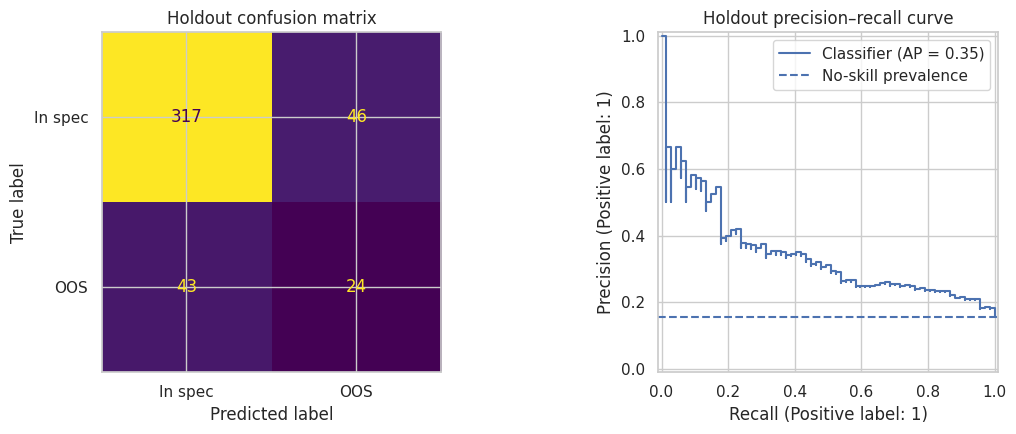

In [10]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred, zero_division=0),
    "recall": recall_score(y_test, y_pred, zero_division=0),
    "f1": f1_score(y_test, y_pred, zero_division=0),
    "pr_auc_average_precision": average_precision_score(y_test, y_probability),
    "roc_auc": roc_auc_score(y_test, y_probability) if y_test.nunique() == 2 else np.nan,
    "test_event_prevalence": y_test.mean(),
}
print(data_mode)
print("Test metrics (0.50 decision threshold):")
display(pd.Series(metrics).rename("score").to_frame().round(3))
print("Classification details:")
print(classification_report(y_test, y_pred, digits=3, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(cm, display_labels=["In spec", "OOS"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Holdout confusion matrix")
PrecisionRecallDisplay.from_predictions(y_test, y_probability, ax=axes[1])
axes[1].axhline(y_test.mean(), linestyle="--", label="No-skill prevalence")
axes[1].set_title("Holdout precision–recall curve")
axes[1].legend()
plt.tight_layout()
plt.show()

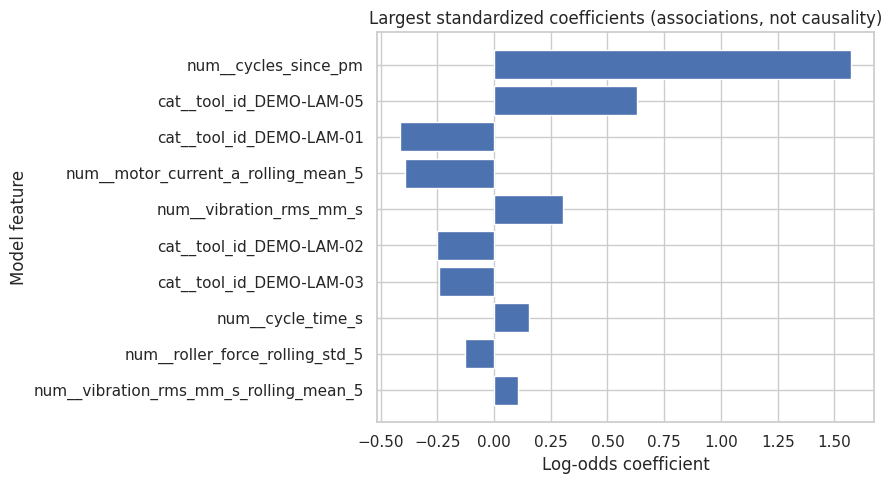

Top model coefficients:


,coefficient
num__cycles_since_pm,1.575
cat__tool_id_DEMO-LAM-05,0.632
cat__tool_id_DEMO-LAM-01,-0.416
num__motor_current_a_rolling_mean_5,-0.391
num__vibration_rms_mm_s,0.305
cat__tool_id_DEMO-LAM-02,-0.252
cat__tool_id_DEMO-LAM-03,-0.242
num__cycle_time_s,0.156
num__roller_force_rolling_std_5,-0.126
num__vibration_rms_mm_s_rolling_mean_5,0.107


In [11]:
feature_names = model.named_steps["preprocess"].get_feature_names_out()
coefficients = pd.Series(model.named_steps["classifier"].coef_[0], index=feature_names)
top_coefficients = coefficients.reindex(coefficients.abs().sort_values(ascending=False).head(10).index)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top_coefficients.index, top_coefficients.values)
ax.invert_yaxis()
ax.set(title="Largest standardized coefficients (associations, not causality)",
       xlabel="Log-odds coefficient", ylabel="Model feature")
plt.tight_layout()
plt.show()
print("Top model coefficients:")
display(top_coefficients.round(3).to_frame("coefficient"))

## 9. Findings, limitations, and recommendations

### Results status

**If using the synthetic fallback:** all counts, plots, coefficients, and evaluation scores are generated from a fabricated process with programmed patterns. They are useful for validating the notebook workflow **but are not business findings**. Do not substitute these values into a README as actual manufacturing results.

**After connecting real data**, replace this section with: dataset size and timeframe; missingness/duplicates; class prevalence; stratified trends by tool/recipe/time; holdout precision, recall and PR-AUC; and engineering interpretation of false negatives/false positives.

### Actionable plan (hypotheses to test)

1. **Condition-based inspection:** investigate tools exhibiting simultaneous force drift, vibration increase and rising next-cycle BLT excursion risk. Validate signals against maintenance records.
2. **Process controls:** verify roller-force, speed, vacuum and tension stability by recipe and material lot, and separate recipes before inferring equipment drift.
3. **Alert economics:** select thresholds after quantifying downtime, engineer-review burden, and cost of escaped BLT excursions.
4. **Prospective validation:** trial alerts in shadow mode first, then compare lead time, false-alarm rate, and defect reduction against current control charts/SPC.

### Risks / limits

- Target predicts next-cycle BLT compliance, **not** actual failure time, maintenance necessity or causal treatment effect.
- The illustrative generator makes some predictors informative by construction; real process data could behave differently.
- Recipes, lots, inspection delays, tooling changes and upstream effects can confound correlations.
- If metrology arrives after the next cycle begins, move to a longer prediction horizon and adjust the feature/label timing.
- Never expose confidential production records, tools, yields, supplier IDs, recipes or proprietary CTQs in a public repo.

## 10. Copy-ready outputs for the README (synthetic or real explicitly labeled)

Run this cell to collect numerical results. In the README, only report real manufacturing conclusions after a real-data run with reviewed label/spec definitions.

In [12]:
print("DATA SOURCE:", data_mode)
print(f"Rows loaded / usable labeled cycles: {len(raw):,} / {len(labeled):,}")
print(f"Next-cycle OOS prevalence: {labeled['next_blt_out_of_spec'].mean():.1%}")
print(f"Chronological train/test: {len(train):,} / {len(test):,}")
for key in ["precision", "recall", "f1", "balanced_accuracy", "pr_auc_average_precision", "test_event_prevalence"]:
    print(f"{key}: {metrics[key]:.3f}")
print("Note: numbers from synthetic fallback are demonstration only.")

DATA SOURCE: SYNTHETIC DEMONSTRATION — NOT FACTORY RESULTS
Rows loaded / usable labeled cycles: 2,150 / 2,145
Next-cycle OOS prevalence: 22.6%
Chronological train/test: 1,710 / 430
precision: 0.343
recall: 0.358
f1: 0.350
balanced_accuracy: 0.616
pr_auc_average_precision: 0.346
test_event_prevalence: 0.156
Note: numbers from synthetic fallback are demonstration only.
